# Импорты

In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
import requests

In [ ]:
# импорт изображения
# image_url_path = r'https://images.wallpaperscraft.ru/image/single/gora_sklon_derevia_888129_3840x2400.jpg'
# image_url_path = r"https://image.pngaaa.com/711/281711-middle.png"

def import_image(image_url_path):
    resp = requests.get(image_url_path, stream=True).raw
    img = np.asarray(bytearray(resp.read()), dtype="uint8")
    img = cv2.imdecode(img, cv2.IMREAD_COLOR)
    orig_image = img.copy()

    return orig_image

# **Практическая работа №1. Основные методы OpenCV. Часть №1**

---

# **Тема №1. Чтение, запись и отображение**



## **Задание 1:**  
Напишите процедуру, которая:

- Считывает цветное изображение в режиме `cv2.IMREAD_COLOR`.
- Преобразует его в оттенки серого с использованием `cv2.cvtColor()`.
- Сохраняет полученное черно-белое изображение на диск.
- Отображает оба изображения (оригинальное цветное и преобразованное черно-белое).




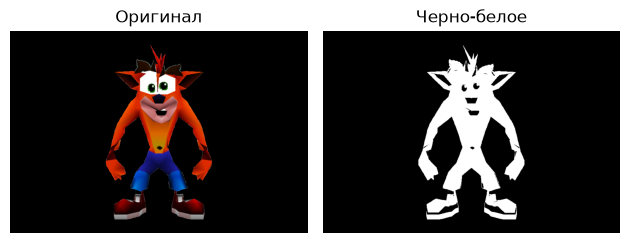

In [41]:
def img_to_grey(img):
    img_color = cv2.imread(img, cv2.IMREAD_COLOR)

    img_gray = cv2.cvtColor(img_color, cv2.COLOR_BGR2GRAY)

    img_black = img_gray.copy()
    value = img_black.mean()

    img_black[img_black > value] = 255
    img_black[img_black <= value] = 0

    cv2.imwrite("task1_black_white.jpg", img_black)

    # Отображение RGB изображения
    img_color_rgb = cv2.cvtColor(img_color, cv2.COLOR_BGR2RGB)
    plt.subplot(1, 2, 1)
    plt.imshow(img_color_rgb)
    plt.title('Оригинал')
    plt.axis('off')

    # Отображение изображения в чёрном белом
    plt.subplot(1, 2, 2)
    plt.imshow(img_black, cmap='gray')
    plt.title('Черно-белое')
    plt.axis('off')

    plt.tight_layout()
    plt.show()

img_to_grey("bandicoot.png")

## **Задание 2:**  
Используя режим `cv2.IMREAD_UNCHANGED`, загрузите изображение с альфа-каналом (например, PNG с прозрачностью). Затем:

- Разделите изображение на каналы (B, G, R, A).
- Создайте новое изображение, где прозрачность (альфа-канал) инвертирована (т.е. прозрачные области становятся непрозрачными и наоборот).
- Сохраните и отобразите полученное изображение.

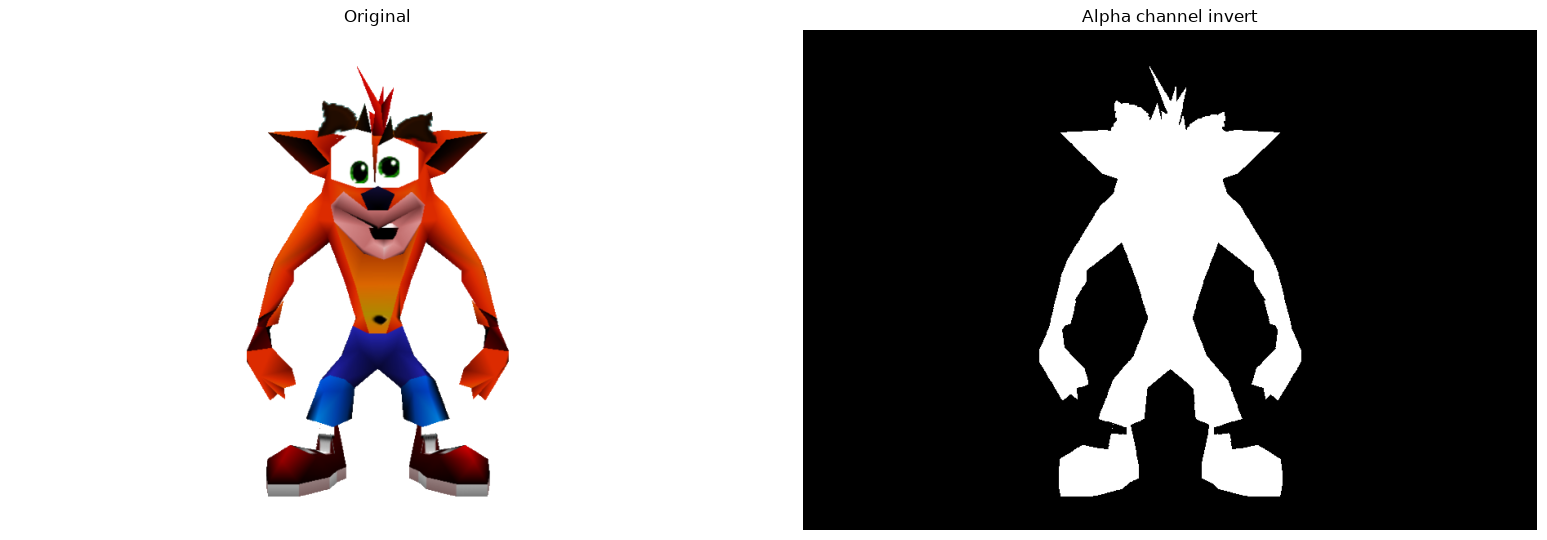

In [ ]:
def alpha_invert(img):
    img_color = cv2.imread(img, cv2.IMREAD_UNCHANGED)

    b, g, r, a = cv2.split(img_color)
    
    a_inverted = 255 - a

    image_inverted = cv2.merge((r, g, b, a_inverted))

    cv2.imwrite("task2_alpha.png", image_inverted)

    fig, ax = plt.subplots(1, 2, figsize=(16, 8))
    fig.tight_layout()

    ax[0].imshow(cv2.cvtColor(img_color, cv2.COLOR_BGR2RGBA))
    ax[0].set_title("Original")
    ax[0].axis("off")

    ax[1].imshow(image_inverted)
    ax[1].set_title("Alpha channel invert")
    ax[1].axis("off")
    plt.show()

alpha_invert("bandicoot.png")

---

# **Тема №2. Работа с цветовыми палитрами**



## **Задание 3:**  
Напишите процедуру, которая:

- Считывает цветное изображение.
- Преобразует его из цветового пространства BGR в HSV с помощью `cv2.cvtColor()`.
- Увеличивает насыщенность (канал S) в 1.5 раза, не превышая максимального значения.
- Преобразует изображение обратно в цветовое пространство BGR.
- Отображает оригинальное и полученное изображения рядом для сравнения.

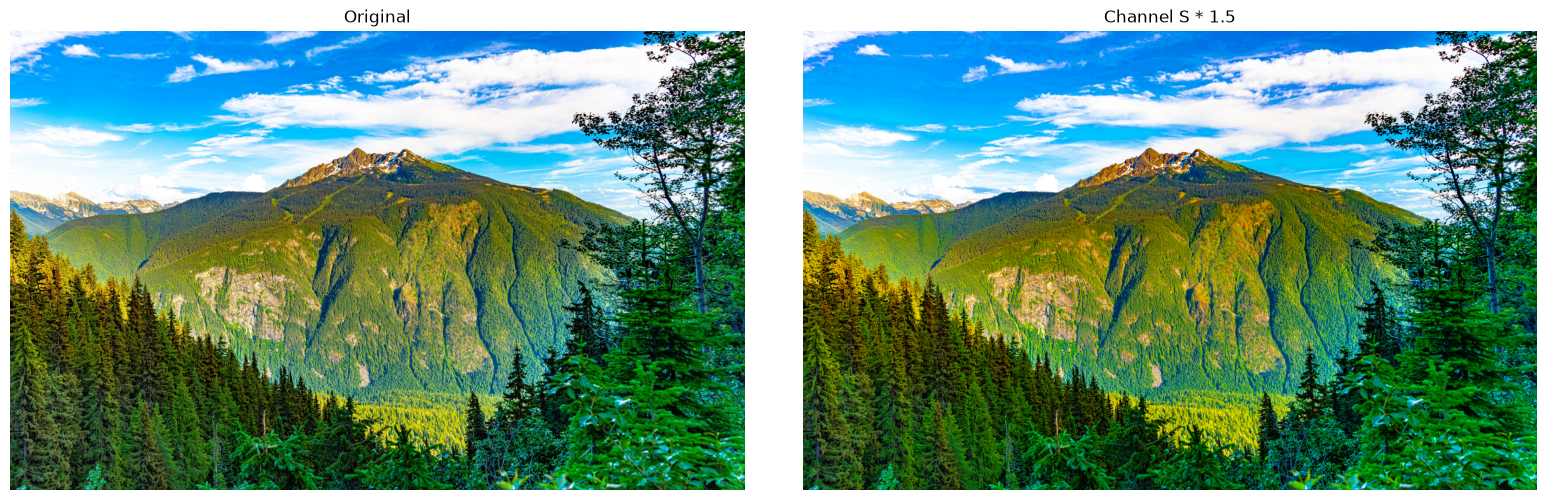

In [40]:
def hsv_multiply_s_channel(img, s_multiply):
    img_color = cv2.imread(img, cv2.IMREAD_COLOR)

    hsv = cv2.cvtColor(img_color, cv2.COLOR_BGR2HSV)

    h_channel, s_channel, v_channel = cv2.split(hsv)

    s_channel_enhanced = cv2.multiply(s_channel, s_multiply)
    s_channel_enhanced = cv2.min(s_channel_enhanced, 255)

    img_enhaced = cv2.merge((h_channel, s_channel_enhanced.astype(np.uint8), v_channel))

    img_enhaced_bgr = cv2.cvtColor(img_enhaced, cv2.COLOR_HSV2BGR)

    fig, ax = plt.subplots(1, 2, figsize=(16, 8))
    fig.tight_layout()

    ax[0].imshow(cv2.cvtColor(img_color, cv2.COLOR_BGR2RGBA))
    ax[0].set_title("Original")
    ax[0].axis("off")

    ax[1].imshow(cv2.cvtColor(img_enhaced_bgr, cv2.COLOR_BGR2RGB))
    ax[1].set_title("Channel S * 1.5")
    ax[1].axis("off")
    plt.show()

hsv_multiply_s_channel("gora.jpg", 1.5)

## **Задание 4:**  
Напишите процедуру, которая:

- Считывает изображение и Преобразует его в цветовое пространство YCrCb.
- Применяет размытие к компоненте яркости Y (при помощи фильтра, см. материал предыдущих занятий).
- Снова Преобразует изображение в цветовое пространство BGR.
- Отображает исходное и размытое изображения.

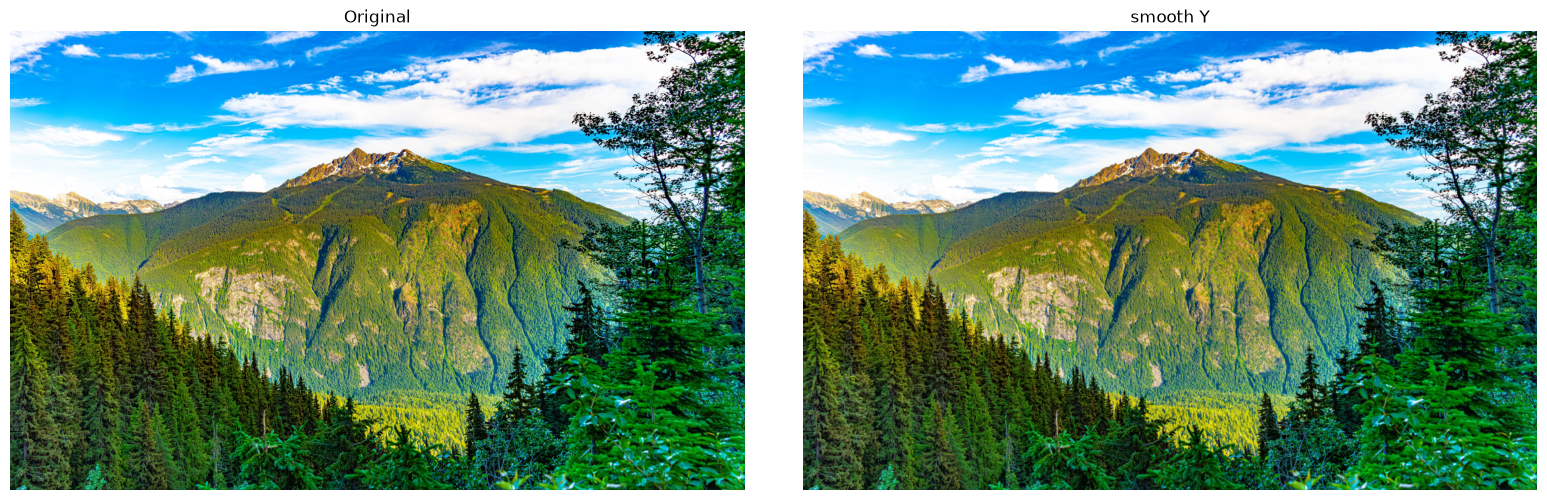

In [37]:
def smooth_Y(img):
    img_color = cv2.imread(img, cv2.IMREAD_COLOR)

    YCrCb = cv2.cvtColor(img_color, cv2.COLOR_BGR2YCrCb)

    Y_channel, Cr_channel, Cb_channel = cv2.split(YCrCb)

    kernel_Gaussian_blur = (1/256) * np.array([
        [1, 4, 6, 4, 1],
        [4, 16, 24, 16, 4],
        [6, 24, 36, 24, 6],
        [4, 16, 24, 16, 4],
        [1, 4, 6, 4, 1]
    ])

    result_smooth = cv2.filter2D(Y_channel, -1, kernel_Gaussian_blur)

    img_enhaced = cv2.merge((result_smooth.astype(np.uint8), Cr_channel, Cb_channel))

    img_enhaced_bgr = cv2.cvtColor(img_enhaced, cv2.COLOR_YCrCb2BGR)

    fig, ax = plt.subplots(1, 2, figsize=(16, 8))
    fig.tight_layout()

    ax[0].imshow(cv2.cvtColor(img_color, cv2.COLOR_BGR2RGBA))
    ax[0].set_title("Original")
    ax[0].axis("off")

    ax[1].imshow(cv2.cvtColor(img_enhaced_bgr, cv2.COLOR_BGR2RGB))
    ax[1].set_title("smooth Y")
    ax[1].axis("off")
    plt.show()

smooth_Y("gora.jpg")

---

# **Тема №3. Слияние и усиление**

## **Задание 5:**  
Создайте процедуру, которая:

- Считывает два изображения одинакового размера (можно подкорректировать с помощью метода `.resize()`).
- Выполняет побитовое ИЛИ (OR) над соответствующими пикселями двух изображений.
- Сохраняет и отображает результат операции.

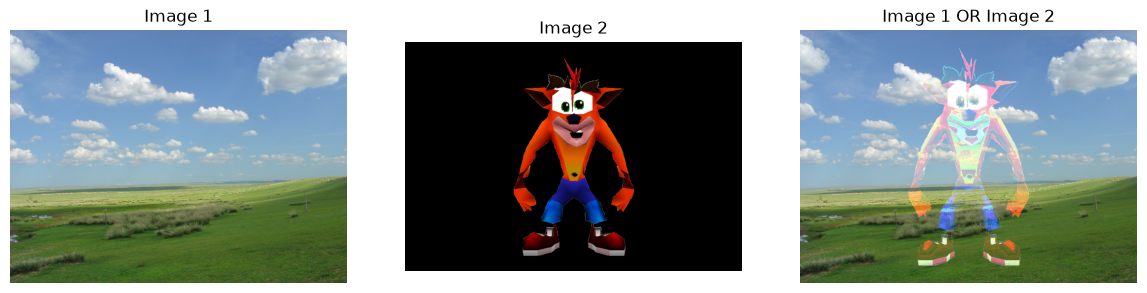

In [45]:
def two_window(img1, img2):
    img1_color = cv2.imread(img1, cv2.IMREAD_COLOR)
    img2_color = cv2.imread(img2, cv2.IMREAD_COLOR)

    img2_resized = cv2.resize(img2_color, (img1_color.shape[1], img1_color.shape[0]))

    result = cv2.bitwise_or(img1_color, img2_resized)

    cv2.imwrite("task_5_bitwise_or.png", result)

    fig, ax = plt.subplots(1, 3, figsize=(12, 4))
    fig.tight_layout()

    ax[0].imshow(cv2.cvtColor(img1_color, cv2.COLOR_BGR2RGB))
    ax[0].set_title("Image 1")
    ax[0].axis("off")

    ax[1].imshow(cv2.cvtColor(img2_color, cv2.COLOR_BGR2RGB))
    ax[1].set_title("Image 2")
    ax[1].axis("off")

    ax[2].imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
    ax[2].set_title("Image 1 OR Image 2")
    ax[2].axis("off")
    plt.show()

two_window("Blue_Sky.png", "bandicoot.png")

## **Задание 6:**  
Реализуйте следующий алгоритм:

- Считайте цветное изображение и разделите его на три канала с использованием `.split()`.
- Примените к каждому каналу разный коэффициент гамма-коррекции (например, для R – 0.5, G – 1.0, B – 1.5).
- Объедините каналы обратно с помощью `.merge()`.
- Отобразите исходное и обработанное изображения.


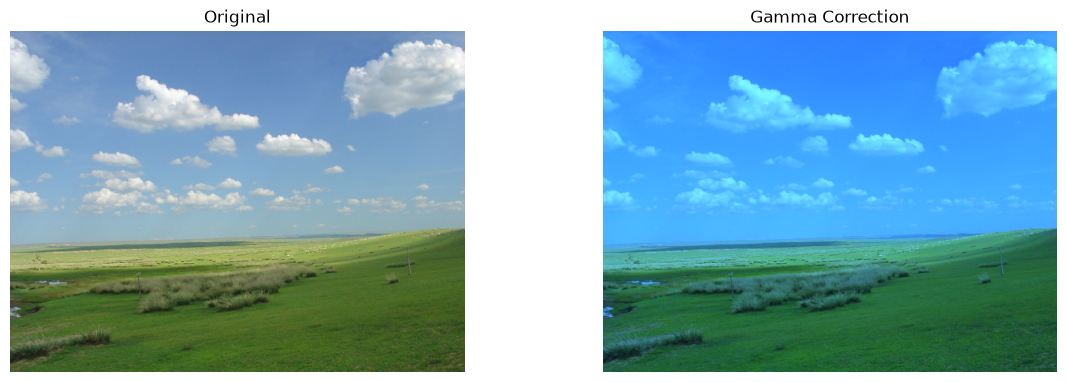

In [76]:
def gamma_correction(img, r_correction, g_correction, b_correction):
    img_color = cv2.imread(img, cv2.IMREAD_COLOR)

    b, g, r = cv2.split(img_color)
    
    r_enhanced = cv2.multiply(r, r_correction)
    g_enhanced = cv2.multiply(g, g_correction)
    b_enhanced = cv2.multiply(b, b_correction)

    img_enhaced = cv2.merge((b_enhanced, g_enhanced, r_enhanced))
    img_enhaced_rgb = cv2.cvtColor(img_enhaced, cv2.COLOR_BGR2RGB)

    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    fig.tight_layout()

    ax[0].imshow(cv2.cvtColor(img_color, cv2.COLOR_BGR2RGB))
    ax[0].set_title("Original")
    ax[0].axis("off")

    ax[1].imshow(img_enhaced_rgb)
    ax[1].set_title("Gamma Correction")
    ax[1].axis("off")

    plt.show()
gamma_correction("Blue_Sky.png", 0.5, 1.0, 1.5)

---

# **Тема №4. Работа с гистограммами в OpenCV**

## **Задание 7:**  
Напишите процедуру для улучшения контрастности изображения:

- Считывает изображение в оттенках серого.
- Строит его гистограмму с использованием `cv.calcHist()`.
- Применяет эквализацию гистограммы методом `cv2.equalizeHist()`.
- Отображает на одном графике исходное и эквализованное изображения вместе с их гистограммами.

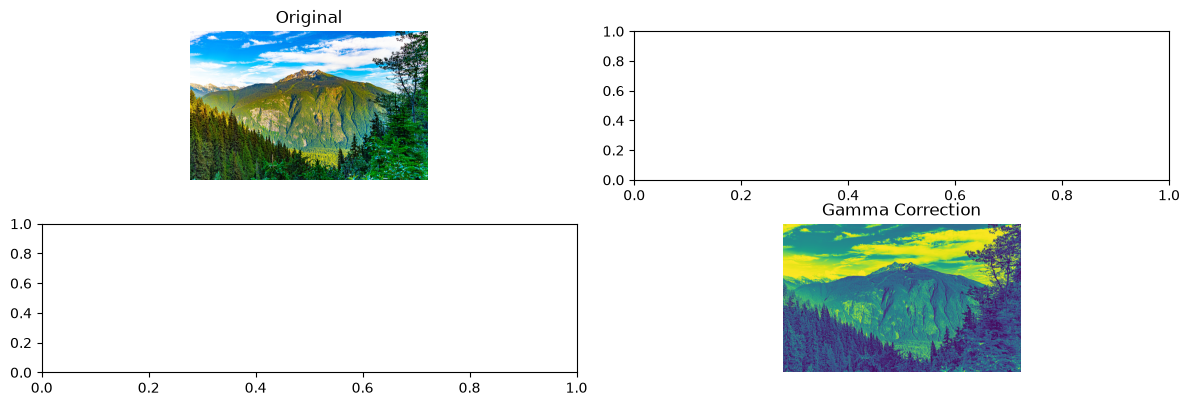

In [79]:
def upgrade_constration_image(img):
    img_color = cv2.imread(img, cv2.IMREAD_COLOR)

    img_gray = cv2.cvtColor(img_color, cv2.COLOR_BGR2GRAY)
    hist = cv2.calcHist(
        [img_gray],
        [0],
        None,
        [256],
        [0, 256]
        )
    eq_hist = cv2.equalizeHist(img_gray)

    fig, ax = plt.subplots(2, 2, figsize=(12, 4))
    fig.tight_layout()

    ax[0][0].imshow(cv2.cvtColor(img_color, cv2.COLOR_BGR2RGB))
    ax[0][0].set_title("Original")
    ax[0][0].axis("off")

    ax[1][1].imshow(img_gray)
    ax[1][1].set_title("Gamma Correction")
    ax[1][1].axis("off")

    plt.show()

upgrade_constration_image("gora.jpg")


## **Задание 8:**  
Используйте метод CLAHE для улучшения деталей в затемненных областях цветного изображения:

- Преобразуйте изображение из BGR в LAB цветовое пространство.
- Разделите изображение на каналы и примените `cv2.createCLAHE()` к каналу яркости L.
- Объедините обработанный канал L с исходными каналами A и B.
- Преобразуйте изображение обратно в BGR.
- Отобразите исходное и обработанное изображения для сравнения вместе с их гистограммами.

In [ ]:
# Ваш код

## **Затем:**  
Исследуйте влияние размера окна (tileGridSize) и порога по сравнению с гистограммой (clipLimit) в методе CLAHE на конечный результат. Попробуйте несколько различных значений и визуализируйте результаты.


In [ ]:
# Ваш код

---

# **Комплексное задание №1. Улучшение качества отсканированного документа с использованием OpenCV**



## **Краткое описание задания:**

- Необходимо написать функцию для улучшения качества отсканированного документа с использованием методов обработки изображений, изученных ранее. Функция должна принимать на вход изображение отсканированного документа и возвращать его улучшенную версию, готовую для дальнейшего использования, например, для распознавания текста.

Датасет с отсканированными изображениями можно найти в сети Интернет.

---



## **Алгоритм действий:**

#### **Реализуйте функцию на языке Python с использованием библиотеки OpenCV, которая выполняет следующие этапы обработки:**

### **1. Чтение, запись и отображение изображений:**

- Функция должна принимать на вход изображение отсканированного документа (например, в формате JPEG или PNG)
- Проверьте наличие альфа-канала в изображении и, если он присутствует, загрузите изображение в режиме `cv2.IMREAD_UNCHANGED`, иначе используйте `cv2.IMREAD_COLOR`
- Отобразите исходное изображение для визуальной проверки

### **2. Работа с цветовыми палитрами:**

- Преобразуйте изображение в оттенки серого, используя `cv2.cvtColor()` с параметром `cv2.COLOR_BGR2GRAY`.
- Отобразите полученное изображение в оттенках серого.

### **3. Слияние и усиление:**

- Примените медианный фильтр (`cv2.medianBlur()`) для удаления шумов с изображения. Выберите подходящий размер ядра (например, 3 или 5). Отобразите результат.
- Используйте фильтр сглаживания с применением прямой свертки (`cv2.filter2D()`) с заданным ядром для повышения четкости. Например, можно использовать фильтр "Unsharp Masking":
  - Создайте ядро для повышения резкости. Пример ядра:
    ```python
    kernel = np.array([[-1, -1, -1],
                       [-1,  9, -1],
                       [-1, -1, -1]])
    ```
  - Примените фильтр к изображению и отобразите результат.

### **4. Работа с гистограммами:**

- Примените метод CLAHE (Contrast Limited Adaptive Histogram Equalization) для улучшения контрастности изображения:
  - Создайте объект CLAHE с параметрами `clipLimit=2.0` и `tileGridSize=(8,8)`.
  - Примените CLAHE к изображению.
  - отобразите результат.
- Постройте гистограммы яркости исходного и обработанного изображений для сравнения.

---

### **Требования к функции:**

- Функция должна называться: `improve_scan(image)`, где `image` — входное изображение в виде массива NumPy.
- Функция должна возвращать улучшенное изображение в виде массива NumPy.
- В ходе работы функция должна **опционально** отображать промежуточные результаты для наглядности (в условиях Colab использовать соответствующие методы вывода изображений). Для этого следует ввести отдельный параметр (например: `visible=True`) и реализовать с ним соответствующую логику.

---

### **Дополнительные требования:**

- **Обработка ошибок:**
  - Убедитесь, что функция корректно обрабатывает ситуации, когда на вход подается некорректное изображение.
  - Добавьте проверки на тип входных данных.

- **Документация и комментарии:**
  - Функция должна быть снабжена понятной документацией: опишите, какие преобраования выполняются и для чего.
  - Добавьте комментарии к основным участкам кода для пояснения выполняемых действий.



---

### **Подсказки и рекомендации:**


- **Медианный фильтр:**
  Функция `cv2.medianBlur(src, ksize)` принимает на вход изображение и размер ядра (должен быть нечетным числом).

- **CLAHE:**
  - Создайте объект CLAHE с помощью `cv2.createCLAHE(clipLimit, tileGridSize)`.
  - Примените метод `apply()` к изображению в оттенках серого.

- **Отображение изображений в Google Colab:**
  - Используйте `matplotlib.pyplot` для отображения изображений.
  - Помните, что `cv2.imread()` загружает изображения в формате BGR, поэтому для корректного отображения в Matplotlib Преобразуйте изображение в RGB с помощью `cv2.cvtColor(image, cv2.COLOR_BGR2RGB)`.

---

In [ ]:
# Ваш код

## **Дополнительное задание:**

- Поэкспериментируйте с параметрами медианного фильтра, ядром для фильтра повышения резкости и параметрами CLAHE для достижения наилучшего результата.
- Добавьте возможность передачи этих параметров в функцию `improve_scan` для более гибкой настройки обработки. **В качестве параметров по умолчанию установите те, которые показали себя лучше всего по результатам экспериментов**

**Пример с параметрами:**

```python
def improve_scan(image,
                 median_kernel_size=3,
                 sharp_kernel= np.array([[-1, -1, -1],
                                         [-1,  9, -1],
                                         [-1, -1, -1]]),
                 clahe_clip=2.0,
                 clahe_grid=(8,8),
                 visible=True):
    # Реализация с учетом переданных параметров
    ...
```


In [ ]:
# Ваш код